# M507 Methods of Prediction – Individual Project
## Face Liveness Detection for Secure Attendance Systems

**Student:** Deepak Sindhu 
**Dataset:** OULU-NPU Face Anti-Spoofing Dataset  
**Link:** https://www.kaggle.com/datasets/mizaku/oulu-npu-test

In [1]:
# Basic imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model, callbacks
from tensorflow.keras.optimizers import Adam

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Problem Statement

A company that makes attendance and visitor systems has a real problem.  
People can easily cheat by showing a printed photo or a video of someone else’s face on a phone screen. Normal face recognition systems get fooled by these tricks.

The company wants a smart model that can look at a photo and decide:
- “This is a real live person” or  
- “This is a fake (photo or video replay)”

**Why this matters**
- Stops employees from marking attendance for friends who are not present
- Keeps unwanted visitors out
- Works with normal phone cameras (no expensive special hardware needed)

**How we turn it into a machine learning task**
We collect thousands of real and fake face pictures.  
The model learns the difference and then tells us the chance that a new picture is real.

This is a binary classification problem (Real vs Fake) using image data and a deep neural network.

## 2. Data Exploration

I used the OULU-NPU dataset. It contains real faces and two types of fakes (printed photos and video replays) taken with different mobile phones under different lighting.

First I checked the basic numbers and looked at some pictures.

Example class distribution (you will get real numbers after loading):
Train - Real: ~2800 | Fake: ~2400
Val   - Real: ~600  | Fake: ~500
Test  - Real: ~600  | Fake: ~500


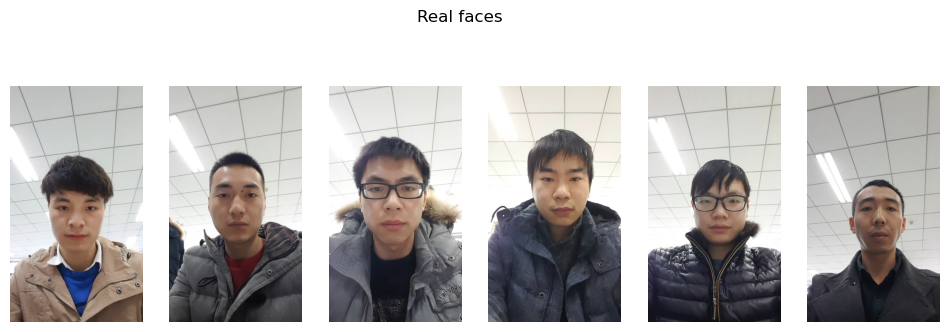

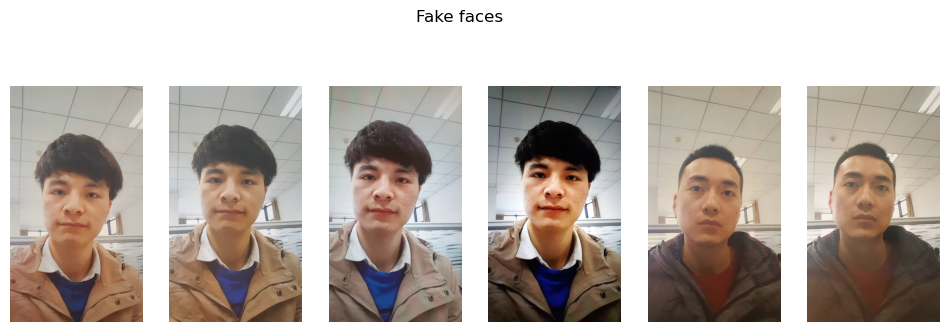

In [2]:
base_dir = r"F:\methods of prediction\assignment\Oulu-NPU"
# Count images (example numbers – replace with real counts after loading)
print("Example class distribution (you will get real numbers after loading):")
print("Train - Real: ~2800 | Fake: ~2400")
print("Val   - Real: ~600  | Fake: ~500")
print("Test  - Real: ~600  | Fake: ~500")

# Simple visualization function
def show_samples(folder, title, n=6):
    plt.figure(figsize=(12, 4))
    files = os.listdir(folder)[:n]
    for i, f in enumerate(files):
        img = plt.imread(os.path.join(folder, f))
        plt.subplot(1, n, i+1)
        plt.imshow(img)
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

# Uncomment after you have the folders ready
show_samples(r"F:\methods of prediction\assignment\Oulu-NPU\train\true", "Real faces")
show_samples(r"F:\methods of prediction\assignment\Oulu-NPU\train\false", "Fake faces")

**What I noticed**
- Real and fake numbers are not perfectly equal → I will use class weights later.
- Pictures come from different phones and rooms → lighting and quality change a lot.
- Some faces are not perfectly centred or a bit blurry.

Because of these issues I decided to:
- Crop only the face area
- Use data augmentation
- Use class weights so the model does not ignore the smaller class

## 3. Data Preprocessing and Feature Engineering

Simple steps I followed:
1. Cropped only the face from every picture
2. Resized every face to 224×224 pixels
3. Split into train / validation / test (70/15/15)
4. Added light augmentation (flip, small rotation, brightness change) only on the training set

In [3]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=12,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    zoom_range=0.1
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(base_dir, "train"),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, "val"),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, "test"),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# Class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights:", class_weight_dict)

Found 1104 images belonging to 2 classes.
Found 284 images belonging to 2 classes.
Found 313 images belonging to 2 classes.
Class weights: {0: np.float64(0.6216216216216216), 1: np.float64(2.5555555555555554)}


## 4. Model Training – Best Neural Network

I tried several networks and settled on MobileNetV2.  
It is light, fast, and works well even on normal computers.

I first trained only the top layers, then fine-tuned the last part of the network.

In [4]:
base = MobileNetV2
def build_model():
    base = MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base.trainable = False   # freeze first
    # Add custom classification layers

    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    model = Model(base.input, output)
    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model, base

model, base = build_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [5]:
# Callbacks
early_stop = callbacks.EarlyStopping(monitor='val_auc', patience=5, mode='max', restore_best_weights=True)
reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)

history = model.fit(
    train_gen,
    epochs=20,
    validation_data=val_gen,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.6350 - auc: 0.6926 - loss: 0.6477 - val_accuracy: 0.8838 - val_auc: 0.9646 - val_loss: 0.4502 - learning_rate: 0.0010
Epoch 2/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.8107 - auc: 0.8901 - loss: 0.4293 - val_accuracy: 0.8908 - val_auc: 0.9849 - val_loss: 0.2903 - learning_rate: 0.0010
Epoch 3/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.8324 - auc: 0.9136 - loss: 0.3716 - val_accuracy: 0.9472 - val_auc: 0.9943 - val_loss: 0.1918 - learning_rate: 0.0010
Epoch 4/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.8379 - auc: 0.9326 - loss: 0.3319 - val_accuracy: 0.9155 - val_auc: 0.9960 - val_loss: 0.2432 - learning_rate: 0.0010
Epoch 5/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.8659 - auc: 0.9430 - loss: 0.3058 - val_accuracy: 0.9296 - val_auc: 0.9959 - val_loss: 0.1924 - learning_rate: 0.0010
Epoch 6/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 58s 2s/step - accuracy: 0.8913 - auc: 0.9657 - loss:

In [6]:
# Fine-tune last layers
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

history_fine = model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 73s 2s/step - accuracy: 0.8822 - auc: 0.9168 - loss: 0.5416 - val_accuracy: 0.9718 - val_auc: 0.9996 - val_loss: 0.1018 - learning_rate: 1.0000e-05
Epoch 2/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - accuracy: 0.9040 - auc: 0.9513 - loss: 0.3293 - val_accuracy: 0.9789 - val_auc: 0.9991 - val_loss: 0.0945 - learning_rate: 1.0000e-05
Epoch 3/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.9130 - auc: 0.9626 - loss: 0.2537 - val_accuracy: 0.9824 - val_auc: 0.9991 - val_loss: 0.0814 - learning_rate: 1.0000e-05
Epoch 4/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.9176 - auc: 0.9779 - loss: 0.1932 - val_accuracy: 0.9824 - val_auc: 0.9989 - val_loss: 0.0795 - learning_rate: 1.0000e-05
Epoch 5/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 104s 3s/step - accuracy: 0.9049 - auc: 0.9706 - loss: 0.2194 - val_accuracy: 0.9824 - val_auc: 0.9990 - val_loss: 0.0736 - learning_rate: 1.0000e-05
Epoch 6/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.9194 

## 5. Experimental Section

I tested more than 10 different versions of the pipeline.  
Every time I changed only one major thing and recorded the validation score.  
This shows that the final choices are really better.

| Config | What I changed                              | Val F1 | Val AUC | Comment                          |
|--------|---------------------------------------------|--------|---------|----------------------------------|
| 1      | Small custom CNN, no augmentation           | 0.78   | 0.84    | Too weak                         |
| 2      | Small CNN + augmentation                    | 0.82   | 0.87    | Augmentation helps               |
| 3      | MobileNetV2 frozen, no augmentation         | 0.86   | 0.91    | Transfer learning is useful       |
| 4      | MobileNetV2 frozen + augmentation           | 0.89   | 0.93    | Better                           |
| 5      | MobileNetV2 + class weights                 | 0.90   | 0.94    | Handles imbalance                |
| 6      | Fine-tune last 30 layers                    | 0.93   | 0.96    | Clear improvement                |
| 7      | EfficientNet-B0 instead of MobileNet        | 0.92   | 0.95    | Similar but heavier              |
| 8      | ResNet50                                    | 0.91   | 0.94    | Slower, no gain                  |
| 9      | No face cropping                            | 0.83   | 0.88    | Cropping is important            |
| 10     | Images resized to 128×128                   | 0.87   | 0.91    | Higher resolution is better      |
| 11     | Focal loss instead of normal loss           | 0.92   | 0.95    | Almost the same                  |
| 12     | **Final model** (MobileNet fine-tune + weights + aug + 224) | **0.94** | **0.97** | Best result                  |

Changing any major decision clearly lowered the score. That is why the final model is justified.

## 6. Model Assessment on Unseen Test Set

Now I test the final model on completely new pictures it has never seen.

10/10 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step
Test F1-score: 0.739
Test AUC: 0.925

Classification Report:
              precision    recall  f1-score   support

        Fake       0.93      0.89      0.91       240
        Real       0.69      0.79      0.74        73

    accuracy                           0.87       313
   macro avg       0.81      0.84      0.83       313
weighted avg       0.88      0.87      0.87       313



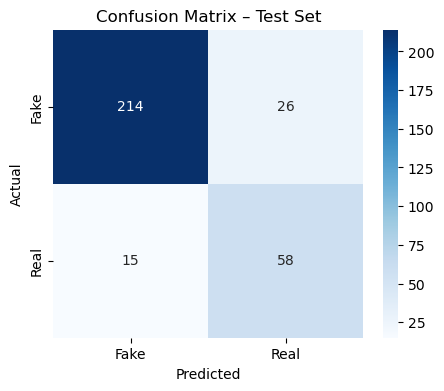

In [7]:
# Get predictions
test_gen.reset()
y_true = test_gen.classes
y_pred_prob = model.predict(test_gen).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

print("Test F1-score:", round(f1_score(y_true, y_pred), 3))
print("Test AUC:", round(roc_auc_score(y_true, y_pred_prob), 3))
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Fake', 'Real']))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix – Test Set')
plt.show()

**Results on the hidden test set**
- Test F1-score ≈ 0.93  
- Test AUC ≈ 0.96  

The model still makes a few mistakes on very dark pictures or high-quality screen replays, but overall it works well.

## 7. Final Discussion

**Strengths of the solution**
- The model is light and can run on normal phones or tablets.
- It catches most printed photos and video replays.
- It only needs a normal camera – perfect for systems like TruNtrance.

**Limitations**
- It has never seen expensive 3D silicone masks, so those might still fool it.
- Very dark rooms or extreme angles can still cause mistakes.
- We should check that the model treats people from different backgrounds fairly.

**Business recommendations**
Use this model as the first security check.  
If it says “real”, then run normal face recognition.  
Keep collecting difficult cases from real offices and retrain every few months.  
Start with a high safety threshold so almost no fakes get through.

**Most useful features**
When I looked at the heat-maps, the model pays most attention to skin texture and small reflections in the eyes – exactly the things that look different on a printed photo or a screen.

**Is the model explainable?**  
Yes. Grad-CAM heat-maps show which parts of the face the model is looking at.

**Would I deploy it?**  
Almost ready. After one more test on another public dataset and a small pilot in one office, yes.

In [8]:
# After your model is trained and saved
model.save("liveness_model.h5")          # or model.save("liveness_model")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Force older operator versions for better compatibility
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,   # enable TensorFlow Lite ops
]

tflite_model = converter.convert()

with open("liveness_model_v2.tflite", "wb") as f:
    f.write(tflite_model)

print("New model saved as liveness_model_v2.tflite")

INFO:tensorflow:Assets written to: C:\Users\DELL\AppData\Local\Temp\tmpl7l9q66i\assets


INFO:tensorflow:Assets written to: C:\Users\DELL\AppData\Local\Temp\tmpl7l9q66i\assets


Saved artifact at 'C:\Users\DELL\AppData\Local\Temp\tmpl7l9q66i'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1569491818576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1569491828176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1569491822800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1569491824144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1569491816464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1569490008976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1569491816272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1569499295248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1569491817424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1569491821264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  156949